# <font color='darkblue'>*Marina Napoleão - EBAC*</font>
## <font color='darkblue'>Projeto duelo de modelos: XGBoost vs SVM</font>

# **Exercicio Duelo de Modelos 4**

Nesta tarefa, vocês irão criar o seu próprio duelo de modelos, com o objetivo de superar os resultados apresentados em aula. O desafio é alcançar um desempenho superior ao que obtivemos, e para isso, será necessário aplicar todas as melhorias que vocês aprenderam ao longo dos módulos, utilizando a base de dados do Titanic.

In [1]:
# Bibliotecas para manipulação de dados
import pandas as pd
import numpy as np

# Bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas para pré-processamento e divisão de dados
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# Bibliotecas para os modelos de machine learning
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Bibliotecas para métricas de avaliação
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [3]:
# Preenchendo valores nulos em Age com a medina
train_df['Age'].fillna(train_df['Age'].median(), inplace=True)
test_df['Age'].fillna(test_df['Age'].median(), inplace=True)
test_df['Fare'].fillna(test_df['Fare'].median(), inplace=True)

C:\Users\marina\AppData\Local\Temp\ipykernel_6752\1101516029.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df['Age'].fillna(train_df['Age'].median(), inplace=True)
C:\Users\marina\AppData\Local\Temp\ipykernel_6752\1101516029.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a 

In [4]:
#Usar Label Encoding, pois há apenas duas categorias
train_df['Sex'] = train_df['Sex'].map({'male': 0, 'female': 1})
test_df['Sex'] = test_df['Sex'].map({'male': 0, 'female': 1})

In [5]:
#Usar One-Hot Encoding, pois há mais de duas categorias
train_df = pd.get_dummies(train_df, columns=['Embarked'], prefix='Embarked')
test_df = pd.get_dummies(test_df, columns=['Embarked'], prefix='Embarked')

In [6]:
#Criar uma nova variável indicando se a cabine é conhecida ou não
train_df['Cabin_known'] = train_df['Cabin'].notna().astype(int)
test_df['Cabin_known'] = test_df['Cabin'].notna().astype(int)

#Deletar a coluna 'Cabin' original
train_df = train_df.drop(columns=['Cabin'])
test_df = test_df.drop(columns=['Cabin'])

In [7]:
train_df = train_df.drop(columns=['Name','Ticket'])  #Deletar as colunas Name e Ticket
test_df = test_df.drop(columns=['Name','Ticket'])

In [8]:
#Converter tipos booleanos para 0 e 1
train_df[['Embarked_C', 'Embarked_Q', 'Embarked_S']] = train_df[['Embarked_C', 'Embarked_Q', 'Embarked_S']].astype(int)
test_df[['Embarked_C', 'Embarked_Q', 'Embarked_S']] = test_df[['Embarked_C', 'Embarked_Q', 'Embarked_S']].astype(int)

In [9]:
variaveis = ['Sex', 'Cabin_known','Fare','Pclass']  #Separar as variaveis

In [10]:
train_df.head(5)

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Cabin_known
0,1,0,3,0,22.0,1,0,7.2500,0,0,1,0
1,2,1,1,1,38.0,1,0,71.2833,1,0,0,1
2,3,1,3,1,26.0,0,0,7.9250,0,0,1,0
3,4,1,1,1,35.0,1,0,53.1000,0,0,1,1
4,5,0,3,0,35.0,0,0,8.0500,0,0,1,0


In [11]:
test_df.head(5)

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Cabin_known
0,892,3,0,34.5,0,0,7.8292,0,1,0,0
1,893,3,1,47.0,1,0,7.0000,0,0,1,0
2,894,2,0,62.0,0,0,9.6875,0,1,0,0
3,895,3,0,27.0,0,0,8.6625,0,0,1,0
4,896,3,1,22.0,1,1,12.2875,0,0,1,0


In [12]:
train_df.to_csv("train_base.csv" , header=True)
test_df.to_csv("test_base.csv" , header=True)

-----------

**1. Escolha do Modelo:**
Selecione um dos modelos que foram explorados nos duelos de modelos ao longo do curso. Pode ser SVM, Random Forest, XGBoost, ou qualquer outro que tenhamos abordado.

In [13]:
train_base = pd.read_csv('train_base.csv')
test_base = pd.read_csv('test_base.csv')

In [14]:
# Separando as variáveis dependentes (Y) e independentes (X) nos dados de treino
X = train_base[variaveis]
Y = train_base['Survived']

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [16]:
model_xgboost = xgb.XGBClassifier()

In [17]:
model_xgboost.fit(X_train, Y_train)
model_xgboost.objective

'binary:logistic'

---------

**2. Aperfeiçoamento:**
**Aplique as técnicas que aprendemos para melhorar o desempenho do seu modelo:**

**Cross Validation:** Avalie a robustez do modelo utilizando validação cruzada para garantir que ele generaliza bem.

In [18]:
cv_scores = cross_val_score(model_xgboost, X, Y, cv=5, scoring='recall')  # cv=5 define 5-fold cross-validation

In [19]:
print(f"Scores de Cross-Validation: {cv_scores}")
print(f"Recall Média: {np.mean(cv_scores):.2f}")
print(f"Desvio Padrão: {np.std(cv_scores):.2f}")

Scores de Cross-Validation: [0.68115942 0.75       0.79411765 0.66176471 0.69565217]
Recall Média: 0.72
Desvio Padrão: 0.05


* <font color='darkblue'>A validação cruzada com 5 folds apresentou um recall médio de aproximadamente 72%, com baixo desvio padrão, indicando boa capacidade de generalização do modelo.</font>

**Balanceamento de Classes:** Se o seu modelo lida com problemas de classes desbalanceadas, explore técnicas como SMOTE, undersampling ou oversampling.

In [20]:
smote = SMOTE(random_state=42)
X_train_balanced, Y_train_balanced = smote.fit_resample(X_train, Y_train)

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


**Padronização e Normalização:** Lembre-se de padronizar os dados, especialmente se for usar modelos que são sensíveis à escala das variáveis.

In [21]:
# Padronizando os dados
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', xgb.XGBClassifier(random_state=42))
])

In [22]:
print("\nDistribuição das classes depois do balanceamento:")
print(Y_train_balanced.value_counts())


Distribuição das classes depois do balanceamento:
Survived
0    444
1    444
Name: count, dtype: int64


* <font color='darkblue'>Apesar do XGBoost não ser sensivel à escala das variaveis, foi aplicado o StandardScaler dentro de umPipeline para garantir a padronização e consistência no fluxo de treinamento.</font>

**Hiperparâmetros:** Utilize GridSearchCV ou RandomSearchCV para encontrar os melhores parâmetros.

In [23]:
param_grid = {
    'model__max_depth': [3, 5, 7],              # Profundidade máxima 
    'model__n_estimators': [50, 100, 200],      # Número de estimadores
    'model__learning_rate': [0.01, 0.1, 0.2],   # Taxa de aprendizado
    'model__subsample': [0.8, 1.0],             # Proporção de amostras usadas para treinar 
    'model__colsample_bytree': [0.8, 1.0],      # Proporção de características
    'model__eval_metric': ['logloss'],          # Metrica de avaliação
    'model__min_child_weight': [1],
}

* <font color='darkblue'>min_child_weight: Soma mínima dos pesos das instâncias (hessiana) necessária em um filho. Se a etapa de particionamento da árvore resultar em um nó folha com a soma dos pesos das instâncias menor que min_child_weight, o processo de construção interromperá o particionamento.</font>

* <font color='darkblue'>eval_metric: Evita warnings e deixa o treinamento mais explícito</font>

* <font color='darkblue'>O ajuste de hiperparâmetros foi realizado usando o GridSearchCV junto de um Pipeline, garantindo que a padronização fosse corretamente aplicada dento de cada fold da validação cruzada.</font>

In [24]:
grid_search = GridSearchCV(
    estimator=pipeline,         # Modelo a ser usado
    param_grid=param_grid,      # Conjunto de parâmetros
    scoring='recall',           # Métrica de avaliação
    cv=5,                       # Número de folds para cross-validation
    n_jobs=-1                   # Usa todos os processadores disponíveis

)

In [25]:
grid_search.fit(X_train_balanced, Y_train_balanced)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=None,
                                                      device=None,
                                                      early_stopping_rounds=None,
                                                      enable_categorical=False,
                                                      eval_metric=None,
                                                      feature_types=None,
                                                      gamma=None,
                                                      grow_policy=None,
                                                      importance_type=...
                                                      multi_strategy=None,
                                                      n_estimators=None,
                                                      n_jobs=None,
                                                      num_parallel_tree=None,
                                                      random_state=42, ...))]),
             n_jobs=-1,
             param_grid={'model__colsample_bytree': [0.8, 1.0],
                         'model__eval_metric': ['logloss'],
                         'model__learning_rate': [0.01, 0.1, 0.2],
                         'model__max_depth': [3, 5, 7],
                         'model__min_child_weight': [1],
                         'model__n_estimators': [50, 100, 200],
                         'model__subsample': [0.8, 1.0]},
             scoring='recall')

In [26]:
# Melhor modelo e parâmetros
print("Melhores Parâmetros:", grid_search.best_params_)
print("\n Melhor recall:", grid_search.best_score_)

Melhores Parâmetros: {'model__colsample_bytree': 0.8, 'model__eval_metric': 'logloss', 'model__learning_rate': 0.2, 'model__max_depth': 7, 'model__min_child_weight': 1, 'model__n_estimators': 200, 'model__subsample': 0.8}

 Melhor recall: 0.8062563840653729


* <font color='darkblue'>Para otimizar o modelo XGBoost, foi aplicado o GridSearchCV com validação cruzada de 5 folds, afim de encontrar a combinação mais adequada de hiperparâmetros. A métrica escolhida foi o recall.</font>

* <font color='darkblue'>O melhor resultado encontrado foi um recall de aproximadamente 80%, demonstrando um bom equilíbrio.</font>

-------------

**3. Submissão no Kaggle:**
Treine o seu modelo com os dados de treino e gere as previsões para os dados de teste. Lembre-se de que o conjunto de teste não possui a variável alvo (y_test), pois a avaliação será feita com base nas submissões no Kaggle.
Submeta suas previsões na competição do Titanic no Kaggle.

In [27]:
best_model_xgboost = grid_search.best_estimator_  #visualização do modelo
y_pred_xgboost = best_model_xgboost.predict(X_train_balanced)  #visualização do modelo

In [28]:
conf_matrix = confusion_matrix(Y_train_balanced, y_pred_xgboost)  #visualização do modelo
print('Matriz de Confusão:')
print(conf_matrix)

relatorio = classification_report(Y_train_balanced, y_pred_xgboost)  #visualização do modelo
print("Relatório de Classificação:")
print(relatorio)

Matriz de Confusão:
[[397  47]
 [ 52 392]]
Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.88      0.89      0.89       444
           1       0.89      0.88      0.89       444

    accuracy                           0.89       888
   macro avg       0.89      0.89      0.89       888
weighted avg       0.89      0.89      0.89       888



----------

In [29]:
X_test_Kaggle = test_base[X_train.columns]  #Submissão no Kaggle

In [30]:
Y_model_xgboost = best_model_xgboost.predict(X_test_Kaggle)  #Submissão no Kaggle

In [31]:
Y_model_xgboost  #Submissão no Kaggle

array([0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,

In [32]:
sub_xgboost = pd.DataFrame({'PassengerId': test_base['PassengerId'], 'Survived':  Y_model_xgboost})  #Submissão no Kaggle

In [33]:
sub_xgboost  #Submissão no Kaggle

,PassengerId,Survived
0,892,0
1,893,1
2,894,1
3,895,0
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [34]:
sub_xgboost.to_csv("xgboost_Kaggle.csv", index=False)  #Submissão no Kaggle

-----------

**4. Entrega:**
Envie o código que você desenvolveu, detalhando cada etapa do seu processo de modelagem, explicando as escolhas feitas e como essas ajudaram a melhorar o modelo.

Junto com o código, envie um print do seu score obtido na plataforma do Kaggle. Esse score será a sua métrica final de avaliação, mostrando como o seu modelo se compara com os demais.

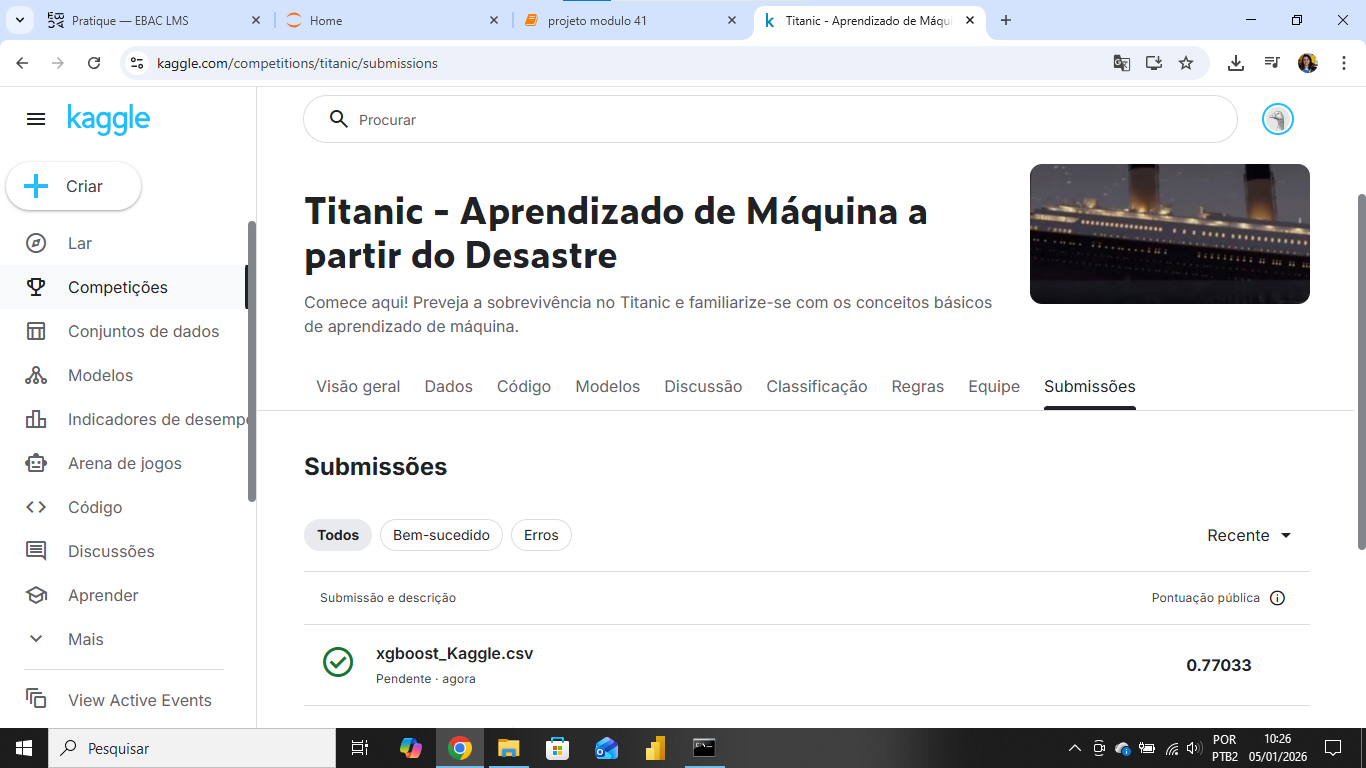

**5. Competição Saudável:**
A ideia é trazer um senso de competição saudável, então não vale replicar exatamente o que fizemos na aula! Inove, explore novas combinações de parâmetros e técnicas, e mostre do que é capaz. O importante é exercitar o pensamento crítico e a capacidade de experimentar.

**Dicas Finais:**

Seja criativo e tenha um olhar crítico sobre o que pode ser melhorado.
Teste diferentes abordagens e não se prenda a um único caminho.
Lembre-se de que, mais do que alcançar o melhor score, o objetivo é aprender e aplicar o conhecimento de forma prática e eficaz.
Boa sorte! Estamos ansiosos para ver como cada um de vocês vai se sair nesse desafio e quais insights irão surgir dessa competição!

Ao final dessa atividade vocês terão participado da primeira competição publica de ciência de dados de vocês = )


